# Metro Interstate Traffic Volume: Task 1 (Preprocessing, Exploratory Analysis, Modelling)

**Dataset:** Metro Interstate Traffic Volume (Kaggle), hourly westbound I-94 traffic near Minneapolis-St Paul, Oct 2012 to Sep 2018, with weather and holiday information.
**Target:** `traffic_volume` (vehicles per hour). **Forecast task:** predict traffic one hour ahead.

## Contents
1. Setup (Drive paths)
2. Task 1A: Understanding the dataset (range, frequency, duplicates, gaps, cleaning, distributions)
3. Task 1B: Analytical questions
   - Q1 Long-term trend
   - Q2 Daily and weekly seasonality
   - Q3 Holiday effects
   - Q4 Lag effects
   - Q5 Moving averages and unusual days
4. Task 1C: Model, experiment table and hyperparameter tuning
5. Handoff to Task 4 (shared feature code and the deployable model)

## How to run
Run the notebook **top to bottom** after the Setup section. The only input is `data/raw/Metro_Interstate_Traffic_Volume.csv` in the Drive project folder. Each section writes its figures to `figures/` and the cleaned data to `data/processed/`.

## Key data decisions (details in the sections below)
| Issue | Decision |
|---|---|
| 7,629 duplicate timestamps (several weather rows per hour) | Collapsed to one row per hour: mean for numeric columns, first value for text |
| 11,976 missing hours (22.8%) after reindexing to a full hourly range | Gaps of 6 hours or less linearly interpolated; the 76 longer gaps (8,928 hours, including a 7,386-hour outage Aug 2014 to Jun 2015) left missing |
| Temperature of 0 K and one rain value of 9,831 mm | Treated as sensor errors and set to missing; temperature converted to Celsius |
| `holiday` labelled only on the first hour of a holiday | Rebuilt as a whole-day flag from the raw data |
| 32 hours (23 Jul 2016 09:00 to 24 Jul 2016 16:00) with near-zero traffic | Set to missing as a suspected sensor or closure fault |
| Model split | Chronological: train through 2016, validation 2017, test 2018 |

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [2]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/traffic_project")
RAW_DIR       = PROJECT / "data" / "raw"
PROCESSED_DIR = PROJECT / "data" / "processed"
FIG_DIR       = PROJECT / "figures"
MODEL_DIR     = PROJECT / "models"

# Create any folders that don't exist yet
for d in [RAW_DIR, PROCESSED_DIR, FIG_DIR, MODEL_DIR]:
    d.mkdir(parents=True, exist_ok=True)

CSV_PATH = RAW_DIR / "Metro_Interstate_Traffic_Volume.csv"
print("CSV exists:", CSV_PATH.exists())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CSV exists: True


## 2. Task 1A: Understanding the dataset
### 2.1 Load and inspect

In [3]:
df = pd.read_csv(CSV_PATH, parse_dates=["date_time"])
print(df.shape)
df.head()

(48204, 9)


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


In [4]:
df.info()
display(df.describe().T)
display(df.describe(include="object").T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   holiday              61 non-null     object        
 1   temp                 48204 non-null  float64       
 2   rain_1h              48204 non-null  float64       
 3   snow_1h              48204 non-null  float64       
 4   clouds_all           48204 non-null  int64         
 5   weather_main         48204 non-null  object        
 6   weather_description  48204 non-null  object        
 7   date_time            48204 non-null  datetime64[ns]
 8   traffic_volume       48204 non-null  int64         
dtypes: datetime64[ns](1), float64(3), int64(2), object(3)
memory usage: 3.3+ MB


,count,mean,min,25%,50%,75%,max,std
temp,48204.0,281.20587,0.0,272.16,282.45,291.806,310.07,13.338232
rain_1h,48204.0,0.334264,0.0,0.0,0.0,0.0,9831.3,44.789133
snow_1h,48204.0,0.000222,0.0,0.0,0.0,0.0,0.51,0.008168
clouds_all,48204.0,49.362231,0.0,1.0,64.0,90.0,100.0,39.01575
date_time,48204,2016-01-05 10:46:16.773711616,2012-10-02 09:00:00,2014-02-06 11:45:00,2016-06-11 03:30:00,2017-08-11 06:00:00,2018-09-30 23:00:00,NaN
traffic_volume,48204.0,3259.818355,0.0,1193.0,3380.0,4933.0,7280.0,1986.86067


,count,unique,top,freq
holiday,61,11,Labor Day,7
weather_main,48204,11,Clouds,15164
weather_description,48204,38,sky is clear,11665


Observations: 48,204 rows and 9 columns. `holiday` is non-null in only 61 rows (NaN means "not a holiday"). `temp` is in Kelvin and has a minimum of 0, and `rain_1h` has a maximum of 9,831 mm, both clear errors (handled in 2.6).

### 2.2 Time range, frequency and duplicates

In [5]:
print("Start:", df["date_time"].min())
print("End:  ", df["date_time"].max())

# Duplicate timestamps
dup_ts = df["date_time"].duplicated().sum()
print("Duplicate timestamps:", dup_ts)
print("Fully identical rows:", df.duplicated().sum())

# Typical spacing between consecutive timestamps
diffs = df["date_time"].sort_values().diff().dropna()
print(diffs.value_counts().head(10))

Start: 2012-10-02 09:00:00
End:   2018-09-30 23:00:00
Duplicate timestamps: 7629
Fully identical rows: 17
date_time
0 days 01:00:00    37986
0 days 00:00:00     7629
0 days 02:00:00     2192
0 days 03:00:00      201
0 days 04:00:00       59
0 days 05:00:00       33
0 days 06:00:00       17
0 days 08:00:00       13
0 days 10:00:00       13
0 days 09:00:00       12
Name: count, dtype: int64


Data runs from 2012-10-02 09:00 to 2018-09-30 23:00 at **hourly** frequency. 7,629 timestamps are repeated (17 rows are fully identical; the rest are the same hour with different weather descriptions). Gaps of 2, 3 or more hours between consecutive rows indicate missing hours.

### 2.3 One row per hour, on a complete hourly index
Duplicates are collapsed and the series is reindexed to every hour in the range, so that missing hours are explicit and `shift(N)` always means N hours back.

In [6]:
df = df.sort_values("date_time")

agg = {
    "holiday": "first",
    "temp": "mean", "rain_1h": "mean", "snow_1h": "mean",
    "clouds_all": "mean", "traffic_volume": "mean",
    "weather_main": "first", "weather_description": "first",
}
ts = df.groupby("date_time").agg(agg)

full_idx = pd.date_range(ts.index.min(), ts.index.max(), freq="h")
ts = ts.reindex(full_idx)
ts.index.name = "date_time"

print("Expected hours:", len(full_idx))
print("Hours present: ", ts["traffic_volume"].notna().sum())
print("Missing hours: ", ts["traffic_volume"].isna().sum())

Expected hours: 52551
Hours present:  40575
Missing hours:  11976


Result: 52,551 expected hours, 40,575 present, 11,976 missing (22.8%).

### 2.4 Where are the gaps?

,start,end,hours
traffic_volume,,,
1792,2014-08-08 02:00:00,2015-06-11 19:00:00,7386
1328,2013-10-27 02:00:00,2013-11-06 03:00:00,242
1804,2015-06-14 21:00:00,2015-06-19 17:00:00,117
1566,2014-04-29 09:00:00,2014-05-04 04:00:00,116
2048,2015-10-23 12:00:00,2015-10-27 07:00:00,92
1778,2014-07-27 17:00:00,2014-07-30 08:00:00,64
832,2013-08-31 01:00:00,2013-09-01 22:00:00,46
1812,2015-06-22 19:00:00,2015-06-24 03:00:00,33
1786,2014-08-02 03:00:00,2014-08-03 10:00:00,32


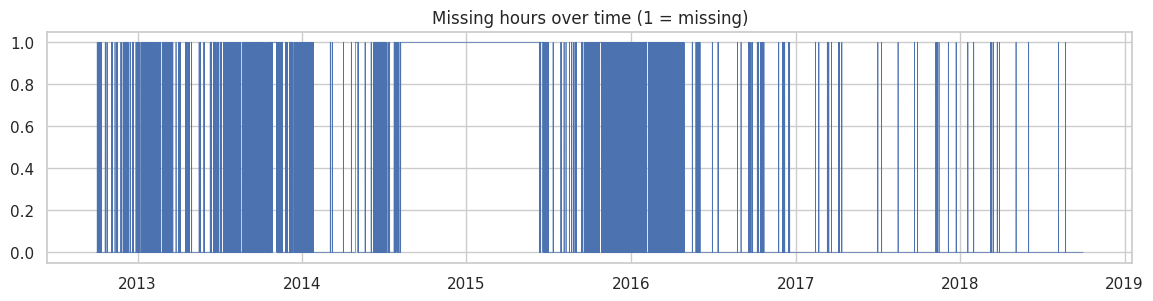

In [7]:
missing = ts["traffic_volume"].isna()
gap_id = (missing != missing.shift()).cumsum()
gaps = (ts[missing].groupby(gap_id[missing])
          .apply(lambda g: pd.Series({"start": g.index[0], "end": g.index[-1], "hours": len(g)})))
gaps = gaps.sort_values("hours", ascending=False)
display(gaps.head(10))

plt.figure(figsize=(14, 3))
plt.plot(ts.index, missing.astype(int), lw=0.5)
plt.title("Missing hours over time (1 = missing)")
plt.show()

One outage dominates: **2014-08-08 to 2015-06-11 (7,386 hours)**. The next longest gaps are 242, 117, 116 and 92 hours.

### 2.5 Impossible values

In [8]:
# temp is in Kelvin; 0 K is a sensor error
ts.loc[ts["temp"] < 200, "temp"] = np.nan
ts["temp_c"] = ts["temp"] - 273.15

# rain_1h has an extreme outlier (~9,831 mm)
print(ts["rain_1h"].sort_values(ascending=False).head())
ts.loc[ts["rain_1h"] > 100, "rain_1h"] = np.nan

date_time
2016-07-11 17:00:00    9831.30
2013-08-07 02:00:00      55.63
2013-06-24 11:00:00      44.45
2016-08-16 17:00:00      31.75
2013-12-19 23:00:00      28.70
Name: rain_1h, dtype: float64


### 2.6 Handling missing values
Short gaps (6 hours or less) are interpolated because traffic changes smoothly over a few hours. Longer gaps are left missing, because interpolating them would invent data. Note that pandas' `interpolate(limit=6)` fills the first 6 hours of a long gap, so those rows are reset to NaN afterwards.

In [9]:
MAX_GAP = 6

# length of the gap each missing hour belongs to
run_len = missing.groupby(gap_id).transform("sum")
long_gap = missing & (run_len > MAX_GAP)

fill_cols = ["traffic_volume", "temp_c", "rain_1h", "snow_1h", "clouds_all",
             "weather_main", "weather_description"]
ts.loc[long_gap, fill_cols] = np.nan

ts = ts.drop(columns="temp")
print("Hours in long gaps:", long_gap.sum())
print(ts.isna().sum())

Hours in long gaps: 8928
holiday                52498
rain_1h                11977
snow_1h                11976
clouds_all             11976
traffic_volume         11976
weather_main           11976
weather_description    11976
temp_c                 11986
dtype: int64


Result: 8,928 hours (17.0%) remain missing, in 76 gaps longer than 6 hours; 3,048 hours (5.8%) were interpolated; 43,623 usable hours (83.0%).

### 2.7 Distributions of numeric columns

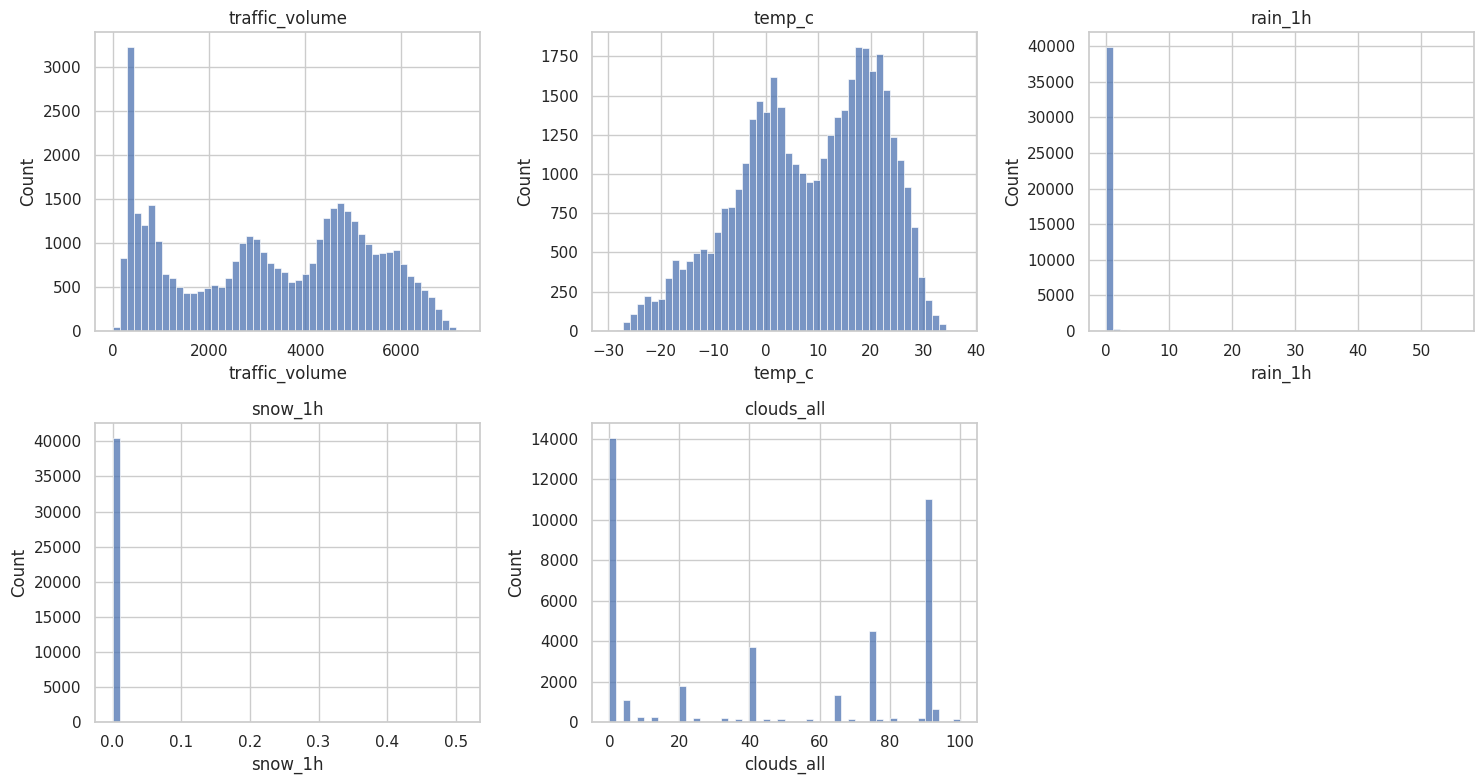

<Axes: title={'center': 'weather_main counts'}, xlabel='weather_main'>

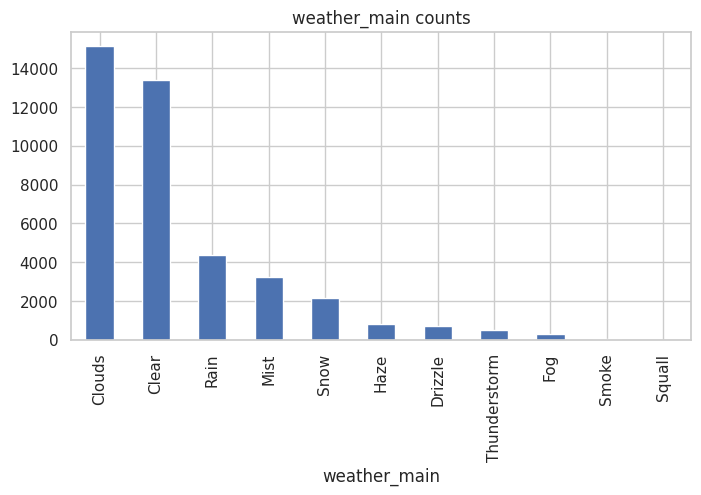

In [11]:
num_cols = ["traffic_volume", "temp_c", "rain_1h", "snow_1h", "clouds_all"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(ts[col].dropna(), bins=50, ax=ax)
    ax.set_title(col)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

ts["weather_main"].value_counts().plot(kind="bar", figsize=(8, 4), title="weather_main counts")

**Interpretation**

- `traffic_volume` is bimodal: a low-volume regime (overnight and early morning, with a spike near 300 to 500) and a high-volume regime (daytime). The mean (about 3,260) sits in the dip between the two humps.
- `temp_c` is bimodal (winter and summer peaks), ranging from about -30 to 35 degrees C. No -273 degrees C values remain.
- `rain_1h` and `snow_1h` are zero in almost every hour. `clouds_all` takes a few discrete values (0, 20, 40, 75, 90).
- `weather_main` is dominated by Clouds and Clear; Smoke and Squall have only a handful of hours.

### 2.8 Save cleaned data and add time features

In [12]:
# Save the cleaned hourly data so you can skip the cleaning after a Colab reset
ts.to_parquet(PROCESSED_DIR / "traffic_clean_hourly.parquet")

# Time features used by most of the analytical questions
ts["hour"] = ts.index.hour
ts["dayofweek"] = ts.index.dayofweek      # 0 = Monday, 6 = Sunday
ts["month"] = ts.index.month
ts["year"] = ts.index.year
ts["is_weekend"] = ts["dayofweek"] >= 5

ts.head()

,holiday,rain_1h,snow_1h,clouds_all,traffic_volume,weather_main,weather_description,temp_c,hour,dayofweek,month,year,is_weekend
date_time,,,,,,,,,,,,,
2012-10-02 09:00:00,None,0.0,0.0,40.0,5545.0,Clouds,scattered clouds,15.13,9,1,10,2012,False
2012-10-02 10:00:00,None,0.0,0.0,75.0,4516.0,Clouds,broken clouds,16.21,10,1,10,2012,False
2012-10-02 11:00:00,None,0.0,0.0,90.0,4767.0,Clouds,overcast clouds,16.43,11,1,10,2012,False
2012-10-02 12:00:00,None,0.0,0.0,90.0,5026.0,Clouds,overcast clouds,16.98,12,1,10,2012,False
2012-10-02 13:00:00,None,0.0,0.0,75.0,4918.0,Clouds,broken clouds,17.99,13,1,10,2012,False


## 3. Task 1B: Analytical questions

### Q1. Is there a long-term trend in traffic volume?
**First pass:** monthly averages with a 12-month rolling mean.

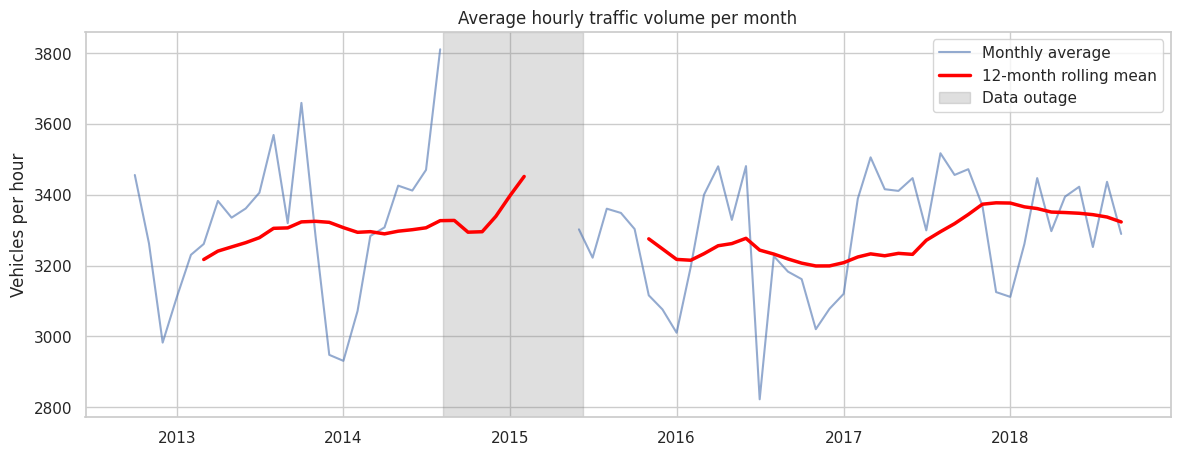

In [13]:
monthly = ts["traffic_volume"].resample("MS").mean()
rolling_12m = monthly.rolling(window=12, min_periods=6).mean()

plt.figure(figsize=(14, 5))
plt.plot(monthly.index, monthly, label="Monthly average", alpha=0.6)
plt.plot(rolling_12m.index, rolling_12m, label="12-month rolling mean", lw=2.5, color="red")
plt.axvspan(pd.Timestamp("2014-08-08"), pd.Timestamp("2015-06-11"),
            color="grey", alpha=0.25, label="Data outage")
plt.title("Average hourly traffic volume per month")
plt.ylabel("Vehicles per hour")
plt.legend()
plt.savefig(FIG_DIR / "q1_long_term_trend.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation**

Average hourly traffic volume shows no strong long-term trend between 2012 and 2018. The 12-month rolling mean stays within roughly 3,200 to 3,400 vehicles per hour, with a mild dip in 2016 and a modest recovery in 2017 to 2018. Month-to-month variation is much larger than the trend and shows a repeating seasonal pattern, with lower volumes in winter. The 2014 to 2015 data outage appears as a gap, and the rolling mean near it is based on few months and should not be over-interpreted. Because the level is stable over time, we do not need to detrend the series before modelling, though we will need to account for seasonality.

**Check:** the plot above includes months with few recorded hours (for example August 2014 has only 123), which creates misleading spikes. How many hours does each month have?

In [14]:
hours_per_month = ts["traffic_volume"].resample("MS").count()
print(hours_per_month[hours_per_month < 600])   # months with under ~80% coverage

date_time
2013-02-01    594
2013-09-01    432
2013-10-01    360
2013-11-01    566
2014-06-01    314
2014-08-01    123
2014-09-01      0
2014-10-01      0
2014-11-01      0
2014-12-01      0
2015-01-01      0
2015-02-01      0
2015-03-01      0
2015-04-01      0
2015-05-01      0
2015-06-01    149
2015-10-01    487
2015-11-01    396
2015-12-01    439
2016-01-01    461
2016-02-01    509
2016-03-01    472
Name: traffic_volume, dtype: int64


**Corrected plot:** keep only months with at least 80% hourly coverage.

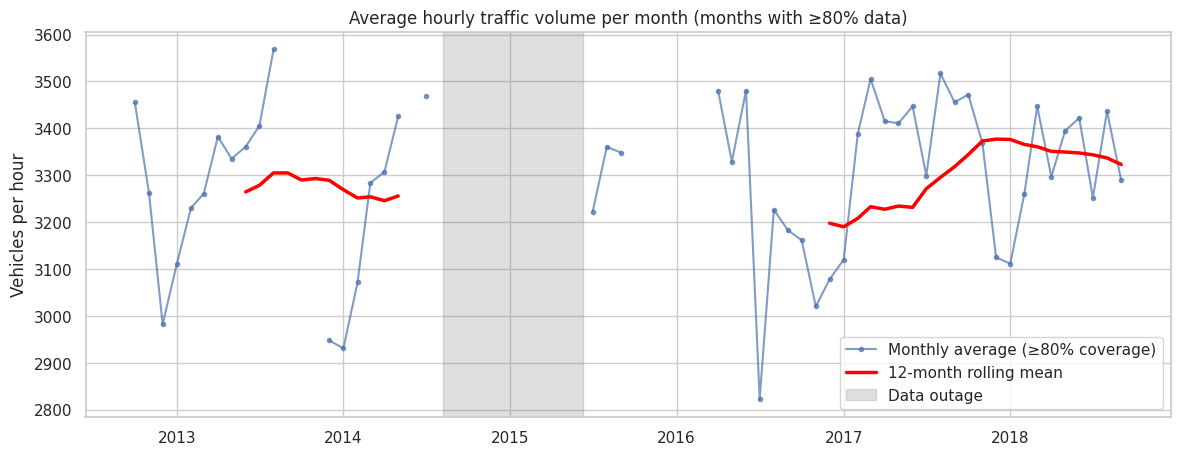

In [15]:
days = monthly.index.days_in_month
coverage = ts["traffic_volume"].resample("MS").count() / (days * 24)

monthly_clean = monthly.where(coverage >= 0.8)       # NaN if under 80% covered
rolling_12m = monthly_clean.rolling(window=12, min_periods=9).mean()

plt.figure(figsize=(14, 5))
plt.plot(monthly_clean.index, monthly_clean, marker="o", ms=3, label="Monthly average (≥80% coverage)", alpha=0.7)
plt.plot(rolling_12m.index, rolling_12m, label="12-month rolling mean", lw=2.5, color="red")
plt.axvspan(pd.Timestamp("2014-08-08"), pd.Timestamp("2015-06-11"),
            color="grey", alpha=0.25, label="Data outage")
plt.title("Average hourly traffic volume per month (months with ≥80% data)")
plt.ylabel("Vehicles per hour")
plt.legend()
plt.savefig(FIG_DIR / "q1_long_term_trend_clean.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation**

After excluding months with less than 80% hourly coverage, the monthly average traffic volume fluctuates around 3,200 to 3,400 vehicles per hour. The 12-month rolling mean is only defined for 2013 to mid-2014 and from late 2016 onward, because of the 2014 to 2015 outage and thin coverage in 2015 to 2016. Where it is defined it varies by under 150 vehicles per hour, so we find no evidence of a strong long-term trend. Month-to-month variation is much larger than any trend, which points to seasonality as the dominant pattern.

**Numeric check:** linear regression of monthly average on time.

In [16]:
from scipy import stats
m = monthly_clean.dropna()
x = (m.index - m.index[0]).days / 365.25
slope, intercept, r, p, se = stats.linregress(x, m.values)
print(f"Slope: {slope:.1f} vehicles/hour per year, p = {p:.3f}, R² = {r**2:.3f}")

Slope: 13.9 vehicles/hour per year, p = 0.263, R² = 0.026


**Result and interpretation** (slope 13.9 vehicles/hour/year, p = 0.263, R-squared = 0.026)

A linear regression of monthly average traffic volume (months with at least 80% coverage) on time gave a slope of 13.9 vehicles per hour per year (p = 0.263, R² = 0.026). The slope is small, not statistically significant, and time explains under 3% of the variance, so we conclude there is no meaningful long-term trend. Most of the variation is seasonal, which we examine next.

### Q2. Daily and weekly seasonality

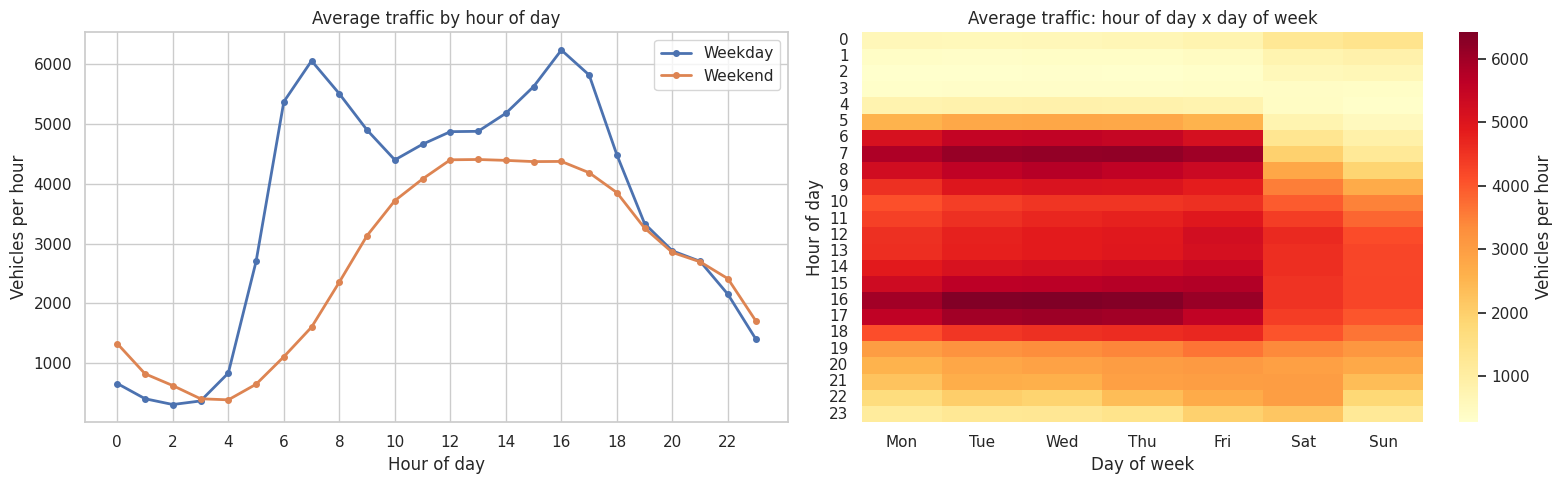

Peak hour (weekday): 16 6241
Peak hour (weekend): 13 4408
Quietest hour (all days): 3 373

Mean by day of week:
dayofweek
Mon    3314.0
Tue    3535.0
Wed    3608.0
Thu    3654.0
Fri    3675.0
Sat    2823.0
Sun    2426.0
Name: traffic_volume, dtype: float64


In [17]:
# --- Q2: Daily and weekly seasonality ---
day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

# Figure 1: average traffic by hour, weekday vs weekend
hourly_profile = (ts.groupby(["is_weekend", "hour"])["traffic_volume"]
                    .mean().unstack(0))
hourly_profile.columns = ["Weekday", "Weekend"]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

hourly_profile.plot(ax=axes[0], marker="o", ms=4, lw=2)
axes[0].set_title("Average traffic by hour of day")
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("Vehicles per hour")
axes[0].set_xticks(range(0, 24, 2))

# Figure 2: heatmap of hour x day of week
heat = (ts.groupby(["dayofweek", "hour"])["traffic_volume"]
          .mean().unstack(0))
heat.columns = day_names
sns.heatmap(heat, cmap="YlOrRd", ax=axes[1], cbar_kws={"label": "Vehicles per hour"})
axes[1].set_title("Average traffic: hour of day x day of week")
axes[1].set_xlabel("Day of week")
axes[1].set_ylabel("Hour of day")

plt.tight_layout()
plt.savefig(FIG_DIR / "q2_daily_weekly_seasonality.png", dpi=150, bbox_inches="tight")
plt.show()

# Numbers to quote in the report
print("Peak hour (weekday):", hourly_profile["Weekday"].idxmax(),
      round(hourly_profile["Weekday"].max()))
print("Peak hour (weekend):", hourly_profile["Weekend"].idxmax(),
      round(hourly_profile["Weekend"].max()))
print("Quietest hour (all days):", ts.groupby("hour")["traffic_volume"].mean().idxmin(),
      round(ts.groupby("hour")["traffic_volume"].mean().min()))
print()
print("Mean by day of week:")
print(ts.groupby("dayofweek")["traffic_volume"].mean().round(0).rename(dict(enumerate(day_names))))

**Interpretation**

- Weekdays have two commuter peaks: 7 am (about 6,050 vehicles per hour) and 4 pm (6,241, the highest point), with a midday dip to about 4,400 at 10 am.
- Weekends have one broad plateau of about 4,400 between noon and 4 pm and no rush-hour peaks. Midnight traffic is higher on weekends (about 1,300 vs 650).
- The quietest hour is 3 am (373). This explains the bimodal histogram of `traffic_volume`.
- Day means: Tuesday to Friday are highest (3,535 to 3,675); Saturday is 2,823 and Sunday 2,426, about 34% below Friday.
- Modelling implication: `hour` and the weekday/weekend type must interact (tree models handle this).

### Q3. How do holidays affect traffic?
The `holiday` column marks only the first hour of a holiday, so a whole-day flag is rebuilt from the raw data. Holiday hours are compared with normal hours at the same hour and weekday/weekend type.

Holiday days in raw data: 53
Holiday hours with traffic data: 1203


,days,pct_vs_normal
holiday_name,,
Christmas Day,5,-50.5
New Years Day,5,-50.3
Thanksgiving Day,5,-44.2
Memorial Day,5,-41.4
Independence Day,5,-40.4
Labor Day,5,-35.5
Martin Luther King Jr Day,3,-23.3
Washingtons Birthday,5,-21.1
Veterans Day,5,-7.9


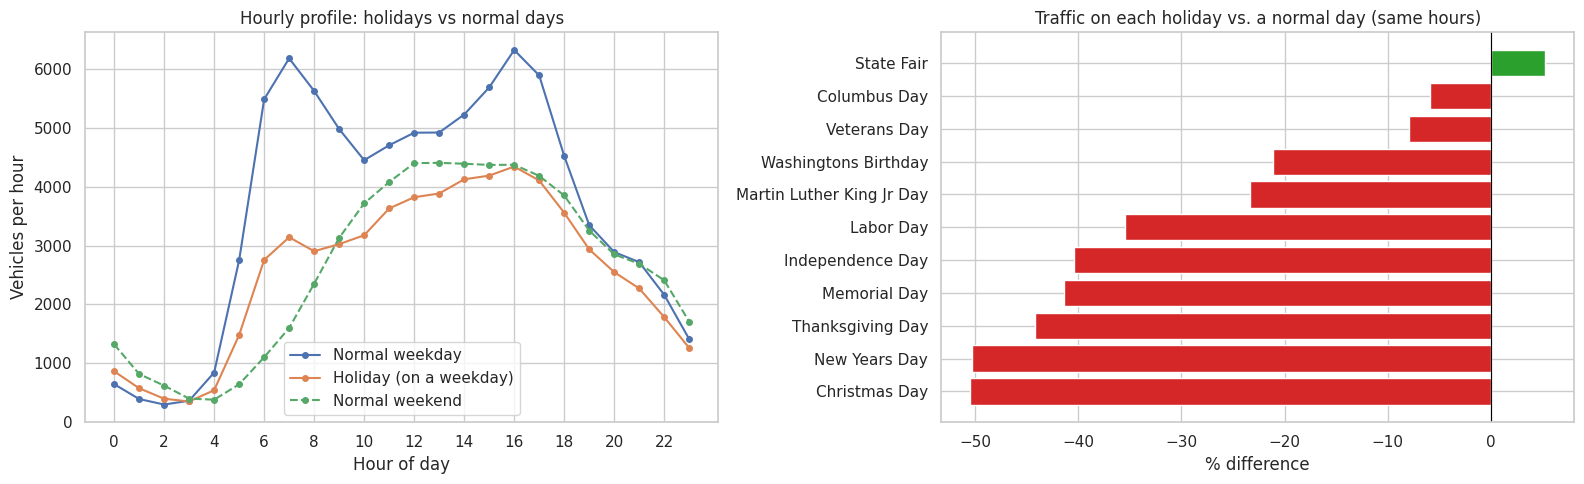

In [18]:
# --- Q3: Effect of holidays on traffic ---

# 1) Rebuild holiday flags from the raw data (the ffilled ts["holiday"] is contaminated)
raw_h = df.loc[df["holiday"].notna(), ["date_time", "holiday"]].copy()
raw_h["date"] = raw_h["date_time"].dt.normalize()
name_map = raw_h.drop_duplicates("date").set_index("date")["holiday"].to_dict()

ts["is_holiday"] = ts.index.normalize().isin(list(name_map.keys()))
ts["holiday_name"] = pd.Series(ts.index.normalize().map(name_map), index=ts.index).fillna("None")
ts = ts.drop(columns="holiday")

print("Holiday days in raw data:", len(name_map))
print("Holiday hours with traffic data:", (ts["is_holiday"] & ts["traffic_volume"].notna()).sum())

# 2) Fair baseline: normal (non-holiday) hours, split by weekday/weekend and hour
profile = (ts[~ts["is_holiday"]]
           .groupby(["is_weekend", "hour"])["traffic_volume"].mean())

h = ts[ts["is_holiday"] & ts["traffic_volume"].notna()].copy()
h["expected"] = profile.reindex(
    pd.MultiIndex.from_arrays([h["is_weekend"], h["hour"]])).values

# 3) Percent difference vs. expected, per holiday
summary = (h.groupby("holiday_name")
             .agg(days=("traffic_volume", lambda s: s.index.normalize().nunique()),
                  actual=("traffic_volume", "sum"),
                  expected=("expected", "sum")))
summary["pct_vs_normal"] = ((summary["actual"] / summary["expected"] - 1) * 100).round(1)
summary = summary.sort_values("pct_vs_normal")
display(summary[["days", "pct_vs_normal"]])

# 4) Plots
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

normal_wd = ts[~ts["is_holiday"] & ~ts["is_weekend"]].groupby("hour")["traffic_volume"].mean()
hol_wd = ts[ts["is_holiday"] & ~ts["is_weekend"]].groupby("hour")["traffic_volume"].mean()
normal_we = ts[~ts["is_holiday"] & ts["is_weekend"]].groupby("hour")["traffic_volume"].mean()
axes[0].plot(normal_wd, marker="o", ms=4, label="Normal weekday")
axes[0].plot(hol_wd, marker="o", ms=4, label="Holiday (on a weekday)")
axes[0].plot(normal_we, marker="o", ms=4, ls="--", label="Normal weekend")
axes[0].set_title("Hourly profile: holidays vs normal days")
axes[0].set_xlabel("Hour of day"); axes[0].set_ylabel("Vehicles per hour")
axes[0].set_xticks(range(0, 24, 2)); axes[0].legend()

colors = ["tab:red" if v < 0 else "tab:green" for v in summary["pct_vs_normal"]]
axes[1].barh(summary.index, summary["pct_vs_normal"], color=colors)
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_title("Traffic on each holiday vs. a normal day (same hours)")
axes[1].set_xlabel("% difference")

plt.tight_layout()
plt.savefig(FIG_DIR / "q3_holiday_effect.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation**

Holidays substantially reduce traffic. On weekday holidays the morning and afternoon commuter peaks shrink (the 7 am peak falls from about 6,200 to about 3,100 vehicles per hour) and the daily profile resembles a weekend. Compared with normal hours at the same time of day, traffic was about 50% lower on Christmas Day and New Year’s Day, 40 to 44% lower on Thanksgiving, Memorial Day and Independence Day, and 21 to 36% lower on Labor Day, Martin Luther King Jr Day and Washington’s Birthday. Veterans Day and Columbus Day showed small reductions (6 to 8%), and State Fair was the only event with higher traffic (+5%). With only 3 to 5 observed days per holiday, these effects are indicative.

### Q4. Are there lag effects?
Correlation of traffic with its value 1, 24 and 168 hours earlier, with and without the average weekday-hour pattern removed.

,lag,correlation,valid_pairs
0,1 h,0.914,37953
1,24 h (1 day),0.865,38345
2,168 h (1 week),0.949,37455


Correlation of deseasonalised traffic: {'lag 1': np.float64(0.82), 'lag 24': np.float64(0.388), 'lag 168': np.float64(0.188)}


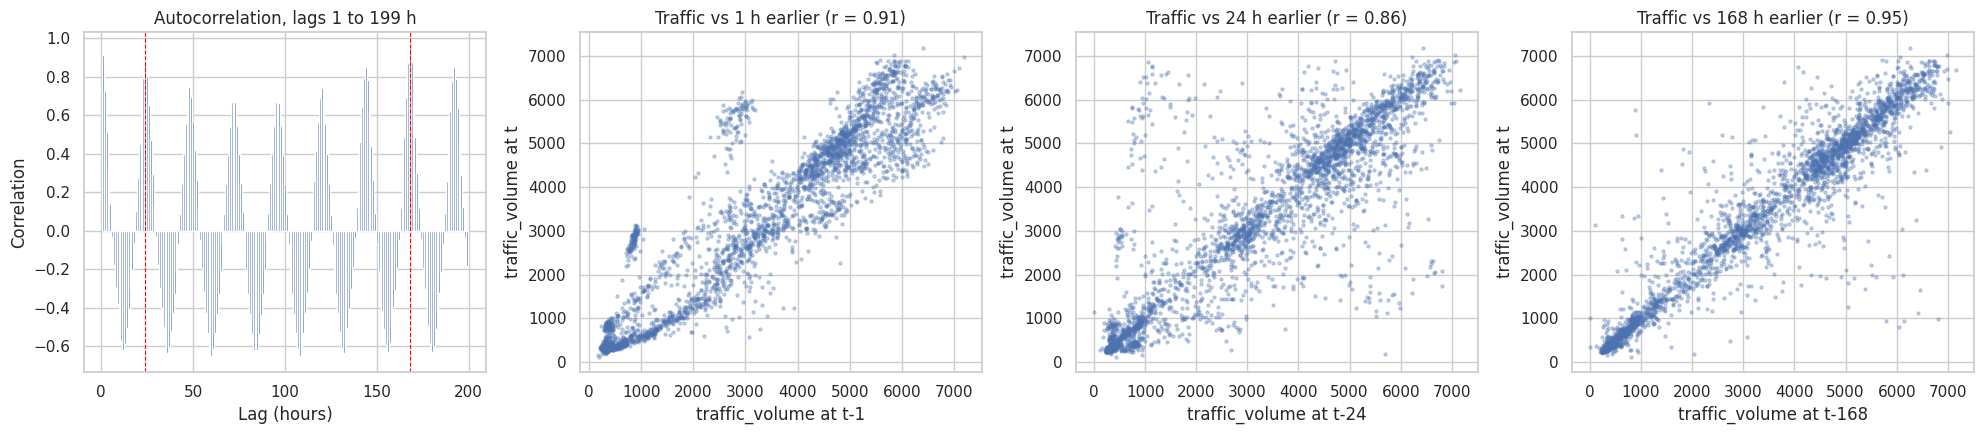

In [25]:
# --- Q4: Lag effects ---

# 1) Lag features. ts is on a complete hourly index, so shift(24) is exactly 24 hours back,
#    even across gaps (the row just becomes NaN).
for lag in [1, 24, 168]:
    ts[f"lag_{lag}"] = ts["traffic_volume"].shift(lag)

# 2) Correlation at each lag, using only hours where both values exist
lags = list(range(1, 200))
acf = pd.Series({k: ts["traffic_volume"].autocorr(lag=k) for k in lags})

key = pd.DataFrame({
    "lag": ["1 h", "24 h (1 day)", "168 h (1 week)"],
    "correlation": [acf[1], acf[24], acf[168]],
    "valid_pairs": [ts[["traffic_volume", f"lag_{k}"]].dropna().shape[0] for k in [1, 24, 168]],
}).round(3)
display(key)

# 3) Lag effect beyond the usual pattern: remove the average value for each weekday-hour slot
slot_mean = ts.groupby(["dayofweek", "hour"])["traffic_volume"].transform("mean")
resid = ts["traffic_volume"] - slot_mean
resid_acf = {k: resid.autocorr(lag=k) for k in [1, 24, 168]}
print("Correlation of deseasonalised traffic:",
      {f"lag {k}": round(v, 3) for k, v in resid_acf.items()})

# 4) Plots
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))

axes[0].bar(acf.index, acf.values, width=1.0)
for k in [24, 168]:
    axes[0].axvline(k, color="red", ls="--", lw=0.8)
axes[0].set_title("Autocorrelation, lags 1 to 199 h")
axes[0].set_xlabel("Lag (hours)"); axes[0].set_ylabel("Correlation")

sample = ts.dropna(subset=["traffic_volume", "lag_1", "lag_24", "lag_168"]).sample(3000, random_state=42)
for ax, k in zip(axes[1:], [1, 24, 168]):
    ax.scatter(sample[f"lag_{k}"], sample["traffic_volume"], s=5, alpha=0.3)
    ax.set_title(f"Traffic vs {k} h earlier (r = {acf[k]:.2f})")
    ax.set_xlabel(f"traffic_volume at t-{k}"); ax.set_ylabel("traffic_volume at t")

plt.tight_layout()
plt.savefig(FIG_DIR / "q4_lag_effects.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation**

| Lag | Raw correlation | After removing weekday-hour average |
|---|---|---|
| 1 h | 0.914 | 0.826 |
| 24 h | 0.864 | 0.395 |
| 168 h | 0.948 | 0.191 |

- The same hour one week earlier is the strongest raw predictor, because it matches both hour and day type. Yesterday is weaker because the day type often changes.
- After removing the seasonal pattern, lags 24 and 168 fall sharply, so they mostly encode the weekly shape. Lag 1 stays high (0.83), so it carries real short-term information.
- Implication: `lag_1` is the most useful lag feature beyond the calendar features. A 24-hour-ahead forecast could not use it.

### Q5. Do moving averages reveal trends or anomalies?
24-hour and 7-day moving averages, plus a search for unusual days (each day's mean compared with the median for the same weekday within about 4 weeks).

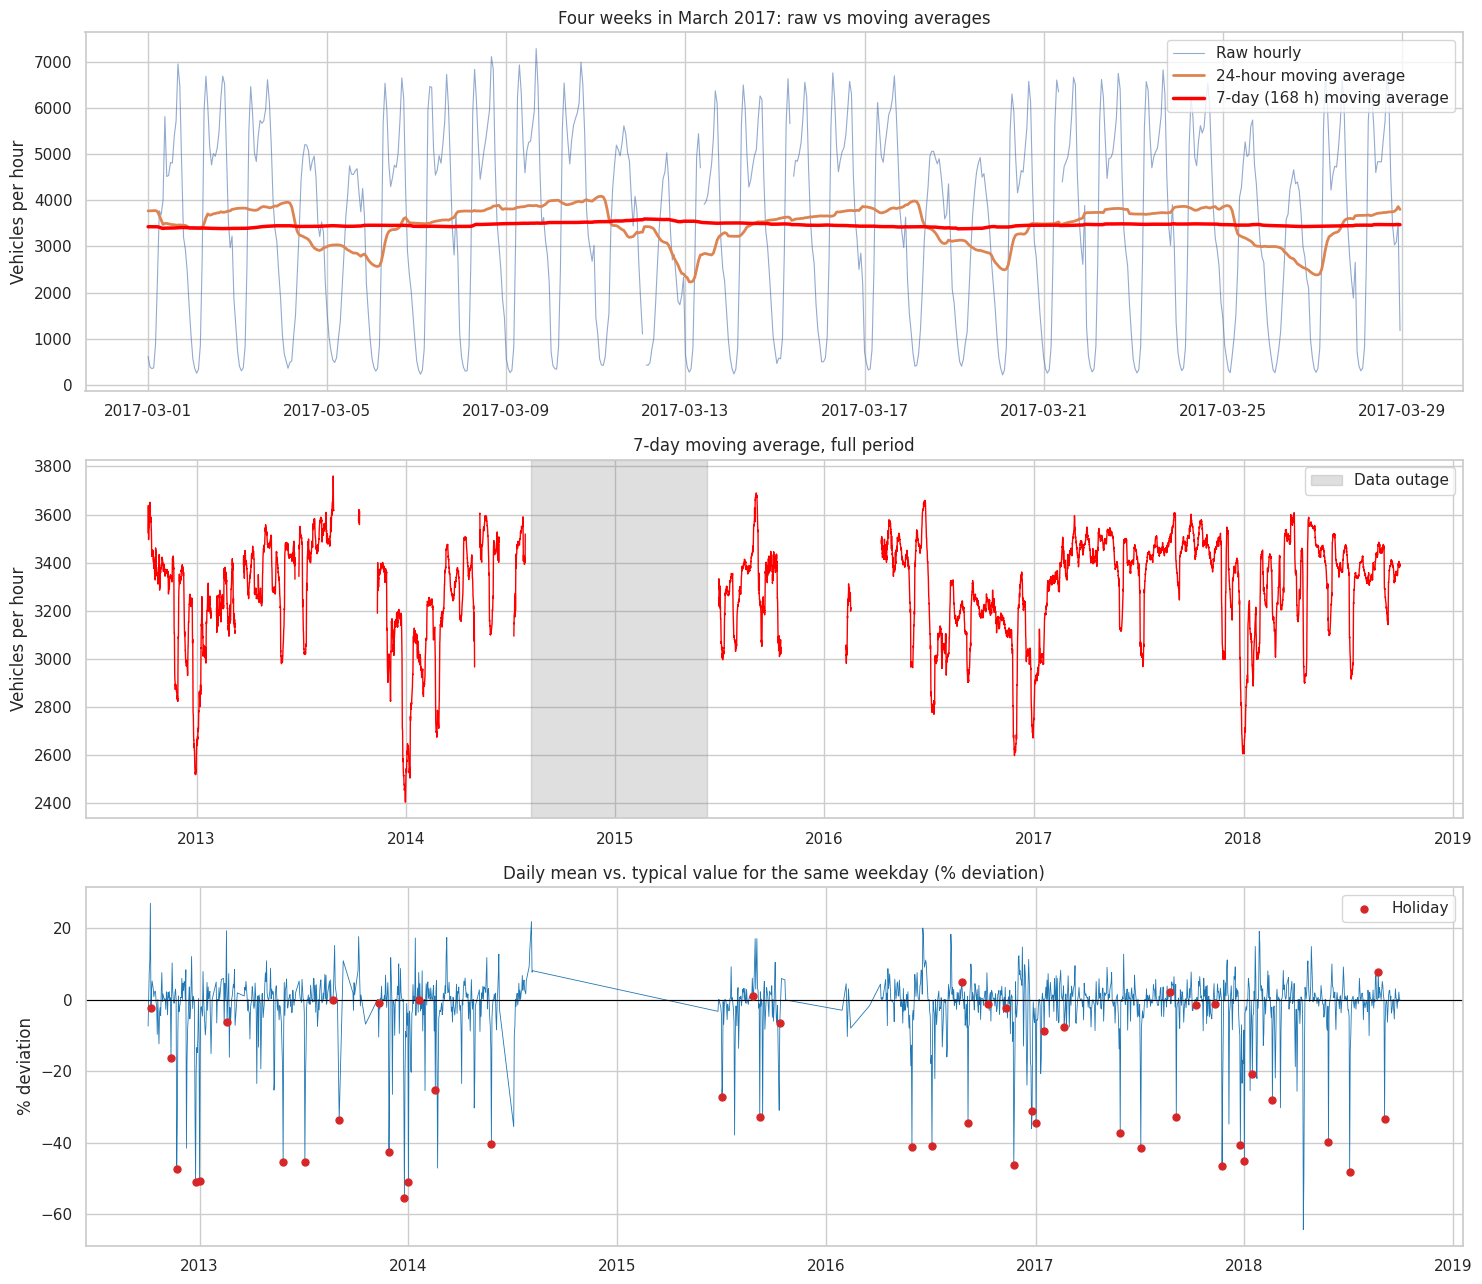

Lowest 10 days vs. typical:


,mean,baseline,dev_pct,holiday
date_time,,,,
2018-04-14,1143.9,3204.8,-64.3,None
2013-12-25,1484.7,3341.5,-55.6,Christmas Day
2014-01-01,1637.5,3341.5,-51.0,New Years Day
2012-12-25,1650.2,3364.5,-51.0,Christmas Day
2013-01-01,1659.0,3364.5,-50.7,New Years Day
2018-04-15,1238.3,2453.0,-49.5,None
2018-07-04,1917.3,3711.7,-48.3,Independence Day
2012-11-22,1974.4,3761.8,-47.5,Thanksgiving Day
2014-02-21,1943.0,3674.5,-47.1,None


Of the 20 lowest days, holidays: 16

Correlation with current traffic:
lag_1     0.913
ma_24     0.180
ma_168    0.081
Name: traffic_volume, dtype: float64
Rows used: 34567


In [26]:
# --- Q5: Moving averages ---
tv = ts["traffic_volume"]

# 1) Moving averages for visualisation (trailing windows; need ~80% of hours present)
ma_24  = tv.rolling(24,  min_periods=19).mean()
ma_168 = tv.rolling(168, min_periods=134).mean()

# 2) Leakage-safe versions to reuse as model features in Task 1C:
#    shift(1) so the average at time t only uses hours up to t-1
ts["ma_24"]  = tv.shift(1).rolling(24,  min_periods=19).mean()
ts["ma_168"] = tv.shift(1).rolling(168, min_periods=134).mean()

# 3) Plots
fig, axes = plt.subplots(3, 1, figsize=(15, 13))

win = slice("2017-03-01", "2017-03-28")
axes[0].plot(tv[win], lw=0.8, alpha=0.6, label="Raw hourly")
axes[0].plot(ma_24[win], lw=2, label="24-hour moving average")
axes[0].plot(ma_168[win], lw=2.5, color="red", label="7-day (168 h) moving average")
axes[0].set_title("Four weeks in March 2017: raw vs moving averages")
axes[0].set_ylabel("Vehicles per hour"); axes[0].legend(loc="upper right")

axes[1].plot(ma_168, color="red", lw=1)
axes[1].axvspan(pd.Timestamp("2014-08-08"), pd.Timestamp("2015-06-11"),
                color="grey", alpha=0.25, label="Data outage")
axes[1].set_title("7-day moving average, full period")
axes[1].set_ylabel("Vehicles per hour"); axes[1].legend()

# 4) Unusual days: daily mean vs. typical value for the same weekday (+/- 4 weeks)
daily = tv.resample("D").agg(["mean", "count"])
daily = daily[daily["count"] >= 20].copy()                      # near-complete days only
daily["dow"] = daily.index.dayofweek
daily["baseline"] = (daily.groupby("dow")["mean"]
                          .transform(lambda s: s.rolling(9, center=True, min_periods=4).median()))
daily["dev_pct"] = (daily["mean"] / daily["baseline"] - 1) * 100
daily["holiday"] = ts["holiday_name"].resample("D").first().reindex(daily.index)

axes[2].plot(daily.index, daily["dev_pct"], lw=0.6, color="tab:blue")
axes[2].axhline(0, color="black", lw=0.8)
hol = daily[daily["holiday"].fillna("None") != "None"]
axes[2].scatter(hol.index, hol["dev_pct"], color="tab:red", s=25, zorder=3, label="Holiday")
axes[2].set_title("Daily mean vs. typical value for the same weekday (% deviation)")
axes[2].set_ylabel("% deviation"); axes[2].legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "q5_moving_averages.png", dpi=150, bbox_inches="tight")
plt.show()

# 5) Numbers for the report
print("Lowest 10 days vs. typical:")
display(daily.nsmallest(10, "dev_pct")[["mean", "baseline", "dev_pct", "holiday"]].round(1))
print("Of the 20 lowest days, holidays:",
      (daily.nsmallest(20, "dev_pct")["holiday"].fillna("None") != "None").sum())

both = ts[["traffic_volume", "lag_1", "ma_24", "ma_168"]].dropna()
print("\nCorrelation with current traffic:")
print(both.corr()["traffic_volume"].drop("traffic_volume").round(3))
print("Rows used:", len(both))

**Interpretation**

- Of the 20 lowest days relative to normal, 14 are public holidays (Christmas and New Year about 50% below normal), consistent with Q3.
- Four non-holiday weekend days stand out: 23 to 24 Jul 2016 (-90%, -62%) and 14 to 15 Apr 2018 (-64%, -50%); investigated below.
- Moving averages correlate weakly with hourly traffic (24 h: 0.184, 7 d: 0.083, against 0.914 for `lag_1`). They describe the recent level, not hourly swings, so they are context features and not replacements for lags.

### 3.1 Investigating the unusual weekends

In [21]:
# Quick checks on the unusual weekend days
check_days = {
    "2016-07-23": "2016-07-24",
    "2018-04-14": "2018-04-15",
}

cols = ["traffic_volume", "temp_c", "rain_1h", "snow_1h", "clouds_all", "weather_main"]

for start, end in check_days.items():
    print("=" * 70)
    print(f"{start} to {end}")
    window = ts.loc[start:end + " 23:00", cols]

    # 1) Coverage: how many hours is the daily mean based on?
    counts = window["traffic_volume"].resample("D").count()
    print("Hours with data per day:\n", counts.to_string(), "\n")

    # 2) Hourly traffic and weather
    display(window)

    # 3) Weather summary for the two days
    print("Weather types:", window["weather_main"].value_counts().to_dict())
    print("Max snow_1h:", window["snow_1h"].max(), "| Max rain_1h:", window["rain_1h"].max())
    print("Temp range (C):", round(window["temp_c"].min(), 1), "to", round(window["temp_c"].max(), 1))

2016-07-23 to 2016-07-24
Hours with data per day:
 date_time
2016-07-23    24
2016-07-24    24
Freq: D 



,traffic_volume,temp_c,rain_1h,snow_1h,clouds_all,weather_main
date_time,,,,,,
2016-07-23 00:00:00,6.0,22.70,0.00,0.0,1.0,Mist
2016-07-23 01:00:00,8.0,22.05,0.00,0.0,1.0,Clear
2016-07-23 02:00:00,5.0,21.67,0.00,0.0,1.0,Mist
2016-07-23 03:00:00,3.0,21.27,0.00,0.0,1.0,Clear
2016-07-23 04:00:00,7.0,21.04,0.00,0.0,1.0,Clear
2016-07-23 05:00:00,830.0,21.36,0.00,0.0,1.0,Clear
2016-07-23 06:00:00,1350.0,21.33,0.00,0.0,75.0,Clouds
2016-07-23 07:00:00,1868.0,22.81,0.00,0.0,75.0,Clouds
2016-07-23 08:00:00,2497.0,24.99,0.00,0.0,90.0,Clouds


Weather types: {'Clouds': 28, 'Rain': 8, 'Clear': 5, 'Mist': 3, 'Thunderstorm': 3, 'Haze': 1}
Max snow_1h: 0.0 | Max rain_1h: 13.46
Temp range (C): 21.0 to 27.7
2018-04-14 to 2018-04-15
Hours with data per day:
 date_time
2018-04-14    24
2018-04-15    24
Freq: D 



,traffic_volume,temp_c,rain_1h,snow_1h,clouds_all,weather_main
date_time,,,,,,
2018-04-14 00:00:00,625.0,-0.42,0.0,0.0,90.0,Snow
2018-04-14 01:00:00,441.0,-0.53,0.0,0.0,90.0,Snow
2018-04-14 02:00:00,397.0,-0.93,0.0,0.0,90.0,Snow
2018-04-14 03:00:00,309.0,-0.85,0.0,0.0,90.0,Snow
2018-04-14 04:00:00,300.0,-0.85,0.0,0.0,90.0,Haze
2018-04-14 05:00:00,540.0,-0.79,0.0,0.0,90.0,Rain
2018-04-14 06:00:00,986.0,-0.79,0.0,0.0,90.0,Rain
2018-04-14 07:00:00,1311.0,-1.14,0.0,0.0,90.0,Rain
2018-04-14 08:00:00,1489.0,-1.28,0.0,0.0,90.0,Snow


Weather types: {'Snow': 30, 'Fog': 6, 'Haze': 4, 'Rain': 4, 'Mist': 4}
Max snow_1h: 0.0 | Max rain_1h: 0.0
Temp range (C): -5.2 to -0.4


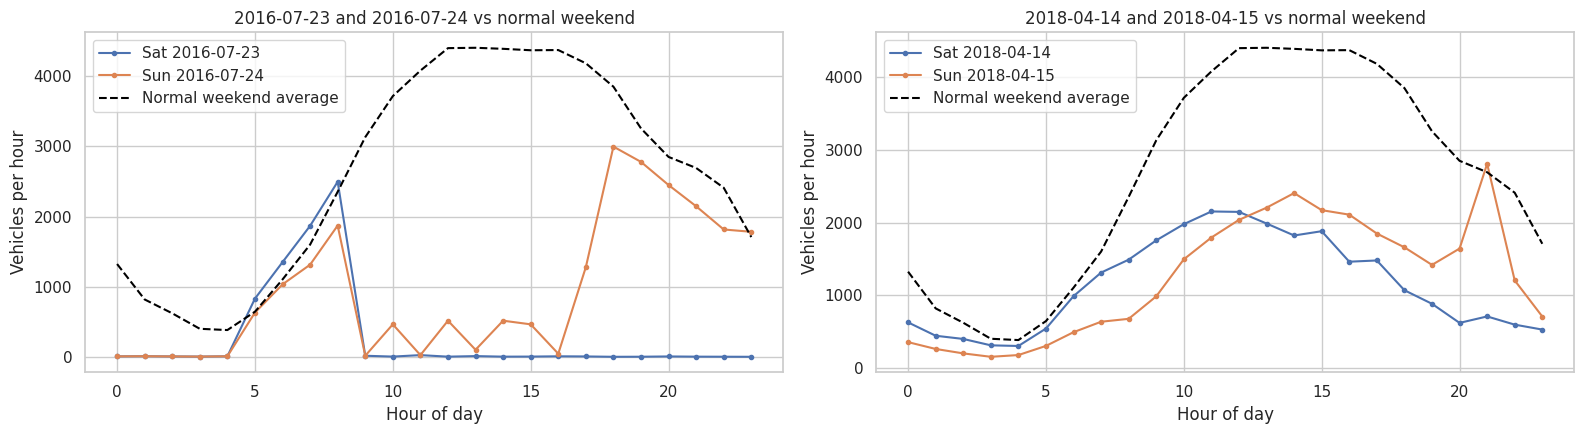

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
normal_we = ts[~ts["is_holiday"] & ts["is_weekend"]].groupby("hour")["traffic_volume"].mean()

for ax, (start, end) in zip(axes, check_days.items()):
    for day in pd.date_range(start, end):
        d = ts.loc[str(day.date()), "traffic_volume"]
        ax.plot(d.index.hour, d.values, marker="o", ms=3, label=day.strftime("%a %Y-%m-%d"))
    ax.plot(normal_we.index, normal_we.values, ls="--", color="black", label="Normal weekend average")
    ax.set_title(f"{start} and {end} vs normal weekend")
    ax.set_xlabel("Hour of day"); ax.set_ylabel("Vehicles per hour")
    ax.legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "q5_unusual_days_check.png", dpi=150, bbox_inches="tight")
plt.show()

**Findings**

- **23 to 24 Jul 2016:** all 24 hours are present each day, but traffic drops from 2,497 to 15 in a single hour at 9 am on both days and stays near zero (Saturday) or erratic (Sunday) until a sudden recovery at 5 to 6 pm on Sunday. Weather does not explain this. It is consistent with a sensor fault or road closure, which the data cannot distinguish.
- **14 to 15 Apr 2018:** a normal weekend shape at about half the usual level, with snow, fog and temperatures from -5.2 to -0.4 degrees C. Treated as a genuine weather effect and kept. Note that `snow_1h` is 0 throughout while `weather_main` reports Snow, so `snow_1h` under-reports snowfall.

### 3.2 Treatment of the suspected faulty hours
The 32 hours (2016-07-23 09:00 to 2016-07-24 16:00) are set to missing. Lag and moving-average columns computed before this point still contain those values, so they are **rebuilt from the cleaned series in Section 4**. (Q4 and Q5 numbers above were computed before this removal; the effect is small.)

In [23]:
bad = slice("2016-07-23 09:00", "2016-07-24 16:00")
print("Hours flagged:", ts.loc[bad, "traffic_volume"].shape[0])
ts.loc[bad, ["traffic_volume", "lag_1", "lag_24", "lag_168", "ma_24", "ma_168"]] = np.nan

Hours flagged: 32


A screen for other near-zero daytime hours on non-holidays:

In [24]:
sus = ts[(ts["traffic_volume"] < 100) & (ts["hour"].between(8, 20)) & (~ts["is_holiday"])]
print(len(sus), "suspicious daytime hours")
print(sus.groupby(sus.index.normalize()).size().sort_values(ascending=False).head(10))

3 suspicious daytime hours
date_time
2015-07-25    2
2016-07-09    1
dtype: int64


Only 3 further hours turned up (2015-07-25 and 2016-07-09), too few to matter, so they are retained. Save the dataset:

In [27]:
ts.to_parquet(PROCESSED_DIR / "traffic_features.parquet")

## 4. Task 1C: Model

**Framing:** predict `traffic_volume` at hour *t* from information available up to *t-1* (lags 1, 24, 168; 24-hour and 7-day moving averages with `shift(1)` to avoid leakage) plus calendar features for hour *t*. Split chronologically: train through 2016, validation 2017, test 2018 (test set used once).

The cell rebuilds all lag and moving-average features from the cleaned series, runs two baselines, Ridge, Random Forest (feature ablation) and an 8-run HistGradientBoosting grid, and saves the experiment table to `data/processed/experiment_table.csv`.

Usable rows: 33187
Train 18162 | Val 8557 | Test 6468


,Experiment,Features,Params,MAE,RMSE,R2
13,HGB: all features (tuning),26 cols,"lr=0.1, depth=8, iters=500",155.623,243.123,0.985
12,HGB: all features (tuning),26 cols,"lr=0.1, depth=8, iters=200",155.663,243.144,0.985
9,HGB: all features (tuning),26 cols,"lr=0.05, depth=8, iters=500",155.946,242.687,0.985
8,HGB: all features (tuning),26 cols,"lr=0.05, depth=8, iters=200",158.466,245.140,0.985
11,HGB: all features (tuning),26 cols,"lr=0.1, depth=4, iters=500",160.561,247.349,0.984
5,RF: all features,26 cols,100 trees,161.145,254.105,0.984
7,HGB: all features (tuning),26 cols,"lr=0.05, depth=4, iters=500",161.157,248.172,0.984
4,RF: calendar + lags + MAs,12 cols,100 trees,161.175,254.155,0.984
10,HGB: all features (tuning),26 cols,"lr=0.1, depth=4, iters=200",164.371,251.936,0.984
6,HGB: all features (tuning),26 cols,"lr=0.05, depth=4, iters=200",173.598,263.754,0.982


Best HGB: {'MAE': 155.6232539271599, 'RMSE': 243.12264987498853, 'R2': 0.9849235931433947, 'lr': 0.1, 'md': 8, 'it': 500}
TEST: {'MAE': 144.534, 'RMSE': 223.671, 'R2': 0.987}
Test baseline (last hour) MAE: 590.4


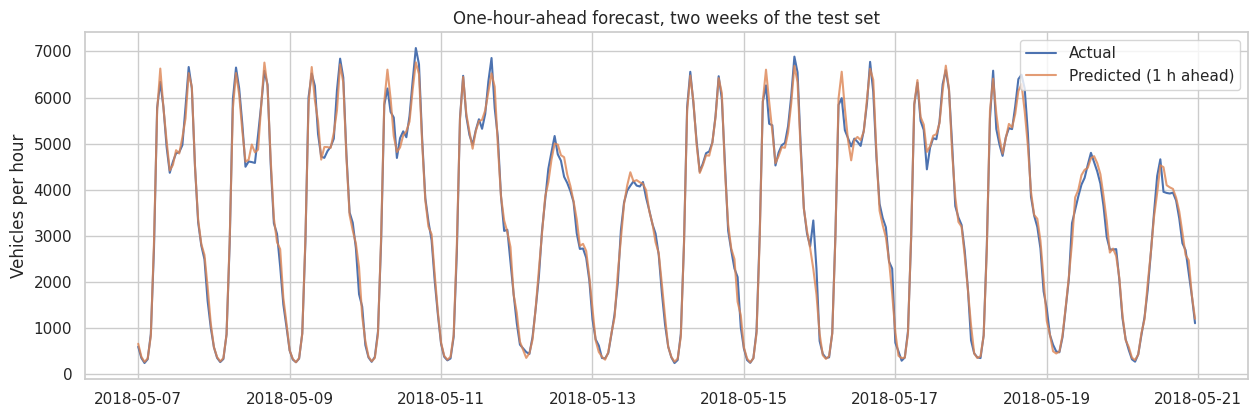

In [28]:
# --- Task 1C: one-hour-ahead forecasting ---
import joblib, itertools
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1) Rebuild features from the CLEANED series (fixes columns affected by the July 2016 removal)
tv = ts["traffic_volume"]
for lag in [1, 24, 168]:
    ts[f"lag_{lag}"] = tv.shift(lag)
ts["ma_24"]  = tv.shift(1).rolling(24,  min_periods=19).mean()   # shift(1): no leakage
ts["ma_168"] = tv.shift(1).rolling(168, min_periods=134).mean()

ts["hour_sin"] = np.sin(2 * np.pi * ts["hour"] / 24)
ts["hour_cos"] = np.cos(2 * np.pi * ts["hour"] / 24)
ts["is_weekend_i"] = ts["is_weekend"].astype(int)
ts["is_holiday_i"] = ts["is_holiday"].astype(int)

wx = ts["weather_main"].replace({"Smoke": "Other", "Squall": "Other"})
wx = pd.get_dummies(wx, prefix="wx", dtype=int)
wx[ts["weather_main"].isna()] = np.nan
wx_cols = list(wx.columns)
data = pd.concat([ts, wx], axis=1)

CAL     = ["hour", "hour_sin", "hour_cos", "dayofweek", "month", "is_weekend_i", "is_holiday_i"]
LAGS    = ["lag_1", "lag_24", "lag_168"]
MAS     = ["ma_24", "ma_168"]
WEATHER = ["temp_c", "rain_1h", "snow_1h", "clouds_all"] + wx_cols
ALL     = CAL + LAGS + MAS + WEATHER

data = data[ALL + ["traffic_volume"]].dropna()
print("Usable rows:", len(data))

# 2) Chronological split (no shuffling)
train = data.loc[:"2016-12-31"]
val   = data.loc["2017-01-01":"2017-12-31"]
test  = data.loc["2018-01-01":]
print(f"Train {len(train)} | Val {len(val)} | Test {len(test)}")

def scores(y, p):
    return {"MAE": mean_absolute_error(y, p),
            "RMSE": mean_squared_error(y, p) ** 0.5,
            "R2": r2_score(y, p)}

results = []

# 3) Baselines (no learning)
for name, col in [("Baseline: repeat last hour", "lag_1"), ("Baseline: same hour last week", "lag_168")]:
    results.append({"Experiment": name, "Features": col, "Params": "-",
                    **scores(val["traffic_volume"], val[col])})

# 4) Experiments on the validation set
def run(name, model, feats, params="-"):
    model.fit(train[feats], train["traffic_volume"])
    s = scores(val["traffic_volume"], model.predict(val[feats]))
    results.append({"Experiment": name, "Features": f"{len(feats)} cols", "Params": params, **s})
    return model

run("Ridge: calendar + lags", make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    CAL + LAGS, "alpha=1")
run("RF: calendar only", RandomForestRegressor(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=42),
    CAL, "100 trees")
run("RF: calendar + lags + MAs", RandomForestRegressor(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=42),
    CAL + LAGS + MAS, "100 trees")
run("RF: all features", RandomForestRegressor(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=42),
    ALL, "100 trees")

# 5) Hyperparameter search for gradient boosting (all features), scored on validation
grid = {"learning_rate": [0.05, 0.1], "max_depth": [4, 8], "max_iter": [200, 500]}
best = {"MAE": np.inf}
for lr, md, it in itertools.product(*grid.values()):
    m = HistGradientBoostingRegressor(learning_rate=lr, max_depth=md, max_iter=it,
                                      l2_regularization=1.0, random_state=42)
    m.fit(train[ALL], train["traffic_volume"])
    s = scores(val["traffic_volume"], m.predict(val[ALL]))
    results.append({"Experiment": "HGB: all features (tuning)", "Features": f"{len(ALL)} cols",
                    "Params": f"lr={lr}, depth={md}, iters={it}", **s})
    if s["MAE"] < best["MAE"]:
        best = {**s, "lr": lr, "md": md, "it": it}

exp = pd.DataFrame(results).round(3)
display(exp.sort_values("MAE"))
exp.to_csv(PROCESSED_DIR / "experiment_table.csv", index=False)
print("Best HGB:", best)

# 6) Final model: refit on train + val, evaluate ONCE on the test set
final = HistGradientBoostingRegressor(learning_rate=best["lr"], max_depth=best["md"],
                                      max_iter=best["it"], l2_regularization=1.0, random_state=42)
trval = pd.concat([train, val])
final.fit(trval[ALL], trval["traffic_volume"])
pred = final.predict(test[ALL])
print("TEST:", {k: round(v, 3) for k, v in scores(test["traffic_volume"], pred).items()})
print("Test baseline (last hour) MAE:", round(mean_absolute_error(test["traffic_volume"], test["lag_1"]), 1))

joblib.dump({"model": final, "features": ALL, "weather_dummies": wx_cols},
            MODEL_DIR / "traffic_model_hgb.joblib")

# 7) Plot two test weeks
wk = test.loc["2018-05-07":"2018-05-20"]
plt.figure(figsize=(15, 4.5))
plt.plot(wk.index, wk["traffic_volume"], label="Actual")
plt.plot(wk.index, final.predict(wk[ALL]), label="Predicted (1 h ahead)", alpha=0.8)
plt.title("One-hour-ahead forecast, two weeks of the test set")
plt.ylabel("Vehicles per hour"); plt.legend()
plt.savefig(FIG_DIR / "model_test_forecast.png", dpi=150, bbox_inches="tight")
plt.show()

### Results

Experiment table (validation set, 2017):

| Experiment | MAE | RMSE | R-squared |
|---|---|---|---|
| Baseline: repeat last hour | 596.6 | 834.7 | 0.822 |
| Baseline: same hour last week | 301.8 | 563.4 | 0.919 |
| Ridge: calendar + lags | 305.1 | 444.0 | 0.950 |
| RF: calendar only | 258.7 | 387.9 | 0.962 |
| RF: calendar + lags + MAs | 161.2 | 254.2 | 0.984 |
| RF: all features (with weather) | 161.1 | 254.1 | 0.984 |
| **HGB: all features, lr=0.1, depth=8, 500 iterations (best)** | **155.6** | **243.1** | **0.985** |

(The HGB grid has 8 runs in total; see the printed table above.)

- **14 runs in the table:** 2 baselines, 1 Ridge, 3 Random Forest and 8 HGB tuning runs.
- Calendar features alone already beat both baselines. Adding lags and moving averages cut MAE by about 38% (259 to 161).
- Weather added nothing (161.2 vs 161.1), because recent traffic already reflects weather.
- Depth mattered most in tuning. The best settings are at the edge of the grid (depth 8, 500 iterations), so a larger grid might improve slightly.
- **Final model (trained on train + validation, scored once on 2018):** MAE 144.5, RMSE 223.7, R-squared 0.987, against 590.4 MAE for repeat-last-hour.
- Caveats: only 33,187 usable rows (rows near gaps lose their lag features); the model never sees mid-2014 to mid-2015; errors are largest at sudden events and sharp transitions.

## 5. Handoff to Task 4

The saved 26-feature model needs weather for the hour being predicted, which a prediction script usually will not have. Since weather added nothing, the cells below retrain the same configuration on the **12 calendar, lag and moving-average features** and put the feature pipeline in a shared file, `src/features.py`, used by both training and the prediction script.

> **Status:** the cells in this section were added during reorganisation and have **not been run yet**. Run them in order and check that the final cell prints a maximum difference of about 0.

### 5.1 Retrain without weather and save

In [ ]:
# --- Retrain without weather: the model the Task 4 script will use ---
import os
os.makedirs(PROJECT / "src", exist_ok=True)

FEATS = CAL + LAGS + MAS            # 12 columns, no weather
d12 = ts[FEATS + ["traffic_volume"]].dropna()
train12 = d12.loc[:"2016-12-31"]
val12   = d12.loc["2017-01-01":"2017-12-31"]
test12  = d12.loc["2018-01-01":]
print(f"Rows: train {len(train12)} | val {len(val12)} | test {len(test12)}")

params = dict(learning_rate=0.1, max_depth=8, max_iter=500,
              l2_regularization=1.0, random_state=42)

# validation score (fit on train only), for the experiment table
m = HistGradientBoostingRegressor(**params).fit(train12[FEATS], train12["traffic_volume"])
print("VAL (no weather):", {k: round(v, 3) for k, v in scores(val12["traffic_volume"], m.predict(val12[FEATS])).items()})

# final model: fit on train + val, score once on the 2018 test set
trval12 = pd.concat([train12, val12])
final12 = HistGradientBoostingRegressor(**params).fit(trval12[FEATS], trval12["traffic_volume"])
print("TEST (no weather):", {k: round(v, 3) for k, v in scores(test12["traffic_volume"], final12.predict(test12[FEATS])).items()})

joblib.dump({"model": final12, "features": FEATS},
            MODEL_DIR / "traffic_model_hgb_12.joblib")

### 5.2 Shared feature code (`src/features.py`)

In [ ]:
%%writefile /content/drive/MyDrive/traffic_project/src/features.py
"""Feature pipeline shared by training (Task 1) and the prediction script (Task 4)."""
import joblib
import numpy as np
import pandas as pd

FEATURES = ["hour", "hour_sin", "hour_cos", "dayofweek", "month",
            "is_weekend_i", "is_holiday_i",
            "lag_1", "lag_24", "lag_168", "ma_24", "ma_168"]

MIN_HISTORY_HOURS = 168   # lag_168 and ma_168 need a week of earlier traffic


def build_features(history, target_time=None, holiday_dates=None):
    """Turn raw traffic records into model features.

    history       DataFrame with columns date_time, traffic_volume
                  (optional: holiday). Duplicate timestamps are averaged.
    target_time   hour to predict. A row for it is appended with no traffic
                  value, so its lags and moving averages use only earlier hours.
                  If None, features are built for every hour in `history`.
    holiday_dates dates (any format pandas parses) that are holidays. Combined
                  with any dates found in a `holiday` column. Pass the target
                  date here, because history alone may not know it is a holiday.
    """
    df = history.copy()
    df["date_time"] = pd.to_datetime(df["date_time"])

    hol = set()
    if holiday_dates is not None and len(holiday_dates) > 0:
        hol |= set(pd.to_datetime(list(holiday_dates)).normalize())
    if "holiday" in df.columns:
        labelled = df["holiday"].notna() & (df["holiday"].astype(str).str.strip().str.lower() != "none")
        hol |= set(df.loc[labelled, "date_time"].dt.normalize())

    # one row per timestamp, then a complete hourly index so shift(N) = N hours back
    s = df.groupby("date_time")["traffic_volume"].mean().sort_index()
    end = s.index.max() if target_time is None else max(pd.Timestamp(target_time), s.index.max())
    s = s.reindex(pd.date_range(s.index.min(), end, freq="h"))
    s.index.name = "date_time"

    out = pd.DataFrame(index=s.index)
    out["hour"] = out.index.hour
    out["hour_sin"] = np.sin(2 * np.pi * out["hour"] / 24)
    out["hour_cos"] = np.cos(2 * np.pi * out["hour"] / 24)
    out["dayofweek"] = out.index.dayofweek
    out["month"] = out.index.month
    out["is_weekend_i"] = (out["dayofweek"] >= 5).astype(int)
    out["is_holiday_i"] = out.index.normalize().isin(list(hol)).astype(int)

    for lag in (1, 24, 168):
        out[f"lag_{lag}"] = s.shift(lag)
    out["ma_24"] = s.shift(1).rolling(24, min_periods=19).mean()
    out["ma_168"] = s.shift(1).rolling(168, min_periods=134).mean()
    out["traffic_volume"] = s
    return out


def predict_next(history, target_time, model_path, holiday_dates=None):
    """Predict traffic_volume for target_time (one hour after the last record)."""
    bundle = joblib.load(model_path)
    feats = build_features(history, target_time, holiday_dates)
    row = feats.loc[[pd.Timestamp(target_time)], bundle["features"]]
    if row.isna().any(axis=None):
        missing = row.columns[row.isna().any()].tolist()
        raise ValueError(f"Not enough history for {target_time}: missing {missing}. "
                         f"Provide at least {MIN_HISTORY_HOURS} hours before it.")
    return float(bundle["model"].predict(row)[0])

### 5.3 Check that `features.py` reproduces the training features
Rebuilds one hour's features from raw history only and compares them with the notebook's own columns. The maximum difference should be about 0.

In [ ]:
import sys, importlib
sys.path.append(str(PROJECT / "src"))
import features; importlib.reload(features)
from features import build_features, FEATURES

t = pd.Timestamp("2018-06-12 17:00")
hist = (ts.loc[t - pd.Timedelta(hours=200): t - pd.Timedelta(hours=1), ["traffic_volume"]]
          .reset_index())
feats = build_features(hist, target_time=t, holiday_dates=list(name_map.keys()))

mine = feats.loc[t, FEATURES].astype(float)
orig = ts.loc[t, FEATURES].astype(float)
print(pd.DataFrame({"build_features": mine, "notebook": orig, "diff": mine - orig}).round(4))
print("Max abs diff:", float((mine - orig).abs().max()))

### Notes for Task 4
- **Files to use:** `src/features.py` and `models/traffic_model_hgb_12.joblib` (a dictionary with `model` and `features`; the feature order must not change).
- **Usage:** `predict_next(history_df, target_time, model_path, holiday_dates)`. The API must return at least the previous 168 hours; `target_time` is one hour after the latest record.
- **Holidays:** the raw data labels a holiday only on its first hour, so pass `holiday_dates` (for example a list of US federal holiday dates) for the target date.
- **Gaps:** if more than about 34 of the last 168 hours are missing, `ma_168` is NaN and the function raises an error instead of guessing.